# Example of calculation for the Arrhenian-like fits
For more details on the calculation of Csw and P1, please check their own scripts.

In [ ]:
from vast_pea.lammps_bonds import bond_dynamics
from vast_pea.lammps_segments import segment
from vast_pea.computers import compute_bond_autocorrelation, compute_legendre_poly
from vast_pea.fitting import fit_KWW, fit_arrhenius_yerr

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
colormap = 'plasma'
cmap = colormaps.get_cmap(colormap).resampled(10) # colormap for plotting multiple temperatures. Using a higher number than the number of temperatures (8) skips the really light yellow colors

temperatures = [325,
                350,
                375,
                400,
                425,
                450,
                500,
                600
                ]

## Bond Autocorrelation Function (Csw)

### Read bond_dynamics and calculate bond autocorrelation function

In [ ]:
# store time and csw for each temperature
time_array = []
csw_array = []

for i, t in enumerate(temperatures):
    bd = bond_dynamics(path="../../data/BER/save/",
                pattern="afd_{}K.bond_data.bonds.nc".format(t),
                restore=True,
                verbose=False
                )

    time = bd.timesteps - 1e6 # -1e6 since the BER part starts at 1ns after equilibration
    csw = compute_bond_autocorrelation(bd.get_bonds_setlist())

    time_array.append(time)
    csw_array.append(csw)

### Fit bond autocorrelation function

In [3]:
# store Csw KWW fits for each temperature
csw_fits = []

for i, t in enumerate(temperatures):
    print("{}K".format(t)) # just to help us knowing which fit print is for which temperature

    kww = fit_KWW(x=time_array[i], # x data to fit, should be a time axis
                  y=csw_array[i], # y data to fit
                  beta_ini=1, # initial beta guess for the KWW fit
                  initial_units='fs', # units of the x data
                  final_units='ps', # units to store tau and tau_average in. Does not change x data
                  verbose=True # whether or not to print fit details
                  )

    csw_fits.append(kww)

325K
Fitting KWW single stretched exponential decay :
	Tau : 657164 ± 153811 picosecond
	Beta : 0.329 ± 0.017 
	R^2 : 0.99
	Tau_average : 4167814 ± 1278356 picosecond
350K
Fitting KWW single stretched exponential decay :
	Tau : 142267 ± 11311 picosecond
	Beta : 0.2701 ± 0.0061 
	R^2 : 1.00
	Tau_average : 2200657 ± 316068 picosecond
375K
Fitting KWW single stretched exponential decay :
	Tau : 89177 ± 6440 picosecond
	Beta : 0.2748 ± 0.0063 
	R^2 : 1.00
	Tau_average : 1260006 ± 175021 picosecond
400K
Fitting KWW single stretched exponential decay :
	Tau : 28416 ± 2036 picosecond
	Beta : 0.320 ± 0.011 
	R^2 : 1.00
	Tau_average : 199940 ± 30860 picosecond
425K
Fitting KWW single stretched exponential decay :
	Tau : 15243 ± 695 picosecond
	Beta : 0.3465 ± 0.0093 
	R^2 : 1.00
	Tau_average : 79401 ± 8369 picosecond
450K
Fitting KWW single stretched exponential decay :
	Tau : 8077 ± 248 picosecond
	Beta : 0.3291 ± 0.0061 
	R^2 : 1.00
	Tau_average : 50867 ± 3945 picosecond
500K
Fitting KWW sing

/home/couture/Dropbox/LIST/vast-pea/vast_pea/fitting.py:27: RuntimeWarning: divide by zero encountered in power
  return np.exp(-(x/tau)**beta)


### Plot Csw and KWW fits

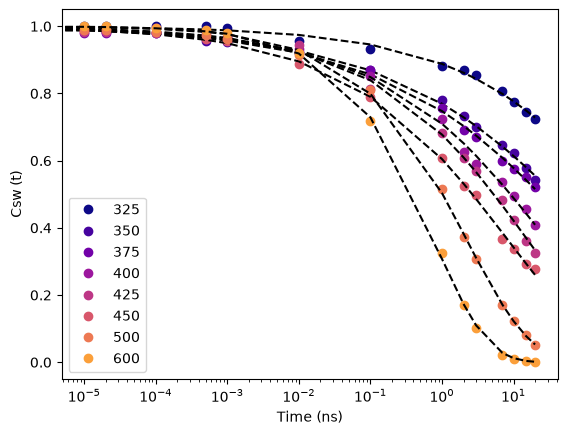

In [ ]:
for i, t in enumerate(temperatures):
    plt.plot(csw_fits[i].x/1e6, csw_fits[i].y, 'o', c=cmap(i), label=t)
    plt.plot(csw_fits[i].x/1e6, csw_fits[i].fitted, '--k')

plt.xscale('log')
plt.xlabel('Time (ns)')
plt.ylabel('Csw (t)')
plt.legend(loc='best')
plt.show()


### Extract average lifetimes

In [ ]:
# store tau_ave and tau_ave_err for each temperature in arrays
csw_lifetimes = np.array([fit.tau_ave for fit in csw_fits])
csw_lifetimes_err = np.array([fit.tau_ave_err for fit in csw_fits])

## Segment Orientation Autocorrelation Function (P1)

### Read segments and calculate segment orientation autocorrelation function

In [ ]:
# store time and p1 for each temperature
time_array = []
p1_array = []

for i, t in enumerate(temperatures):
    seg = segment(traj=None, mass_list=None, identifiers=None,
                  restore=True,
                  restore_path="../../data/BER/save/",
                  restore_pattern="afd_{}K.segment_data.*.nc".format(t),
                  verbose=False
                  )

    time = seg.timesteps - 1e6 # -1 since the BER part starts at 1ns after equilibration
    p1 = compute_legendre_poly(seg.get_vectors().vector, 1)

    time_array.append(time)
    p1_array.append(p1)

### Fit segment orientation autocorrelation function

In [ ]:
# store P1 KWW fits for each temperature
p1_fits = []

for i, t in enumerate(temperatures):
    print("{}K".format(t))

    kww = fit_KWW(x=time_array[i],
                  y=p1_array[i],
                  beta_ini=1,
                  initial_units='fs',
                  final_units='ps',
                  verbose=True
                  )

    p1_fits.append(kww)

325K
Fitting KWW single stretched exponential decay :
	Tau : 149874645 ± 79425724 picosecond
	Beta : 0.270 ± 0.014 
	R^2 : 0.99
	Tau_average : 2308715979 ± 1386302317 picosecond
350K
Fitting KWW single stretched exponential decay :
	Tau : 5637862 ± 1173466 picosecond
	Beta : 0.322 ± 0.010 
	R^2 : 1.00
	Tau_average : 38754762 ± 9426875 picosecond
375K
Fitting KWW single stretched exponential decay :
	Tau : 3325005 ± 467038 picosecond
	Beta : 0.3147 ± 0.0072 
	R^2 : 1.00
	Tau_average : 25033424 ± 4246346 picosecond
400K
Fitting KWW single stretched exponential decay :
	Tau : 1312159 ± 253357 picosecond
	Beta : 0.322 ± 0.012 
	R^2 : 1.00
	Tau_average : 8977412 ± 2181167 picosecond
425K
Fitting KWW single stretched exponential decay :
	Tau : 196390 ± 21366 picosecond
	Beta : 0.401 ± 0.013 
	R^2 : 1.00
	Tau_average : 646261 ± 91940 picosecond
450K
Fitting KWW single stretched exponential decay :
	Tau : 99911 ± 11878 picosecond
	Beta : 0.406 ± 0.018 
	R^2 : 0.99
	Tau_average : 318538 ± 53779

### Plot P1 and KWW fits

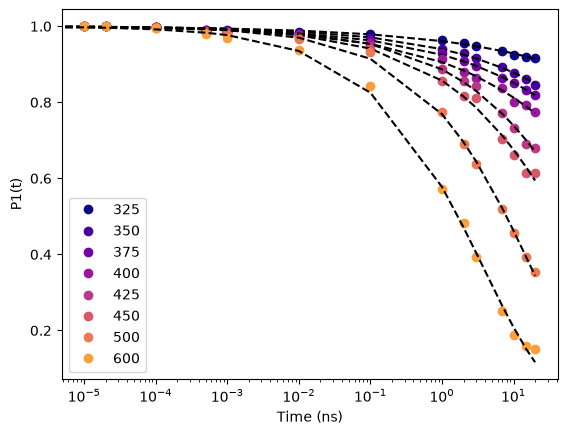

In [8]:
for i, t in enumerate(temperatures):
    plt.plot(p1_fits[i].x/1e6, p1_fits[i].y, 'o', c=cmap(i), label=t)
    plt.plot(p1_fits[i].x/1e6, p1_fits[i].fitted, '--k')

plt.xscale('log')
plt.xlabel('Time (ns)')
plt.ylabel('P1(t)')
plt.legend(loc='best')
plt.show()

### Extract average lifetimes

In [ ]:
# store tau_ave and tau_ave_err for each temperature in arrays
p1_lifetimes = np.array([fit.tau_ave for fit in p1_fits])
p1_lifetimes_err = np.array([fit.tau_ave_err for fit in p1_fits])

## Arrhenian-like fits

### For BER average lifetimes

In [ ]:
csw_arrh = fit_arrhenius_yerr(temperature=temperatures, # temperature for the x axis
                              tau=csw_lifetimes, # lifetimes for the y axis
                              tau_err=csw_lifetimes_err, # lifetime errors
                              initial_units={'temp':'K', 'time':'ps'}, # units of temperature and tau
                              final_units={'energy':'kJ/mol', 'time':'s'}, # wanted units for activation energy and tau. Temperatures will be automatically converted to Kelvins. Time units will be applied on the y data directly before fitting
                              verbose=True # whether or not to print fit details
                              )

Fitting Arrhenius :
	a : 6195 ± 69 K / ln(second)
	b : -31.01 ± 0.13 ln(second)
	R^2 : 0.97
	Activation Energy : 51.50 ± 0.57 kilojoule / mole
	Prefactor : 3.4017535764670238e-14 ± 4.5026728492686476e-15 second


### For segmental average lifetimes

In [11]:
p1_arrh = fit_arrhenius_yerr(temperature=temperatures,
                             property=p1_lifetimes,
                             prop_err=p1_lifetimes_err,
                             initial_units={'temp':'K', 'time':'ps'},
                             final_units={'energy':'kJ/mol', 'time':'s'},
                             verbose=True
                             )

Fitting Arrhenius :
	a : 7452 ± 123 K / ln(second)
	b : -31.54 ± 0.25 ln(second)
	R^2 : 0.92
	Activation Energy : 62.0 ± 1.0 kilojoule / mole
	Prefactor : 2.0106715196284241e-14 ± 5.0176790783197729e-15 second


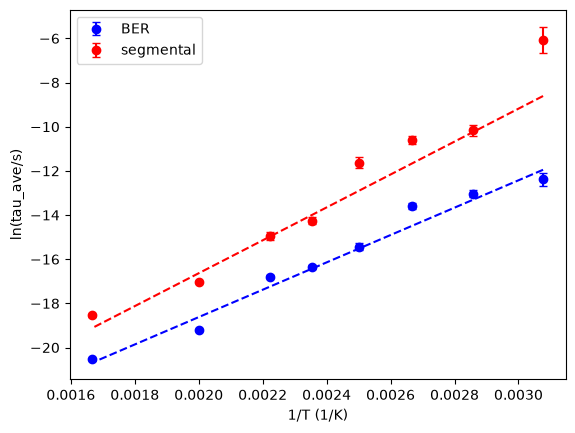

In [17]:
plt.errorbar(csw_arrh.x, csw_arrh.y, csw_arrh.y_err, fmt='ob', capsize=3, label='BER')
plt.plot(csw_arrh.x, csw_arrh.fitted, '--b')
plt.errorbar(p1_arrh.x, p1_arrh.y, p1_arrh.y_err, fmt='or', capsize=3, label='segmental')
plt.plot(p1_arrh.x, p1_arrh.fitted, '--r')

plt.xlabel('1/T (1/K)')
plt.ylabel('ln(tau_ave/s)')
plt.legend(loc='best')
plt.show()